In [1]:
from collections import defaultdict
from pathlib import Path

import matplotlib as mpl
import numpy as np
import pandas as pd
from matplotlib import patheffects as mpe
from matplotlib import pyplot as plt
from matplotlib import ticker as mtick
from numpy.polynomial import Polynomial
from scipy import stats

In [2]:
plots = Path("plots") / "quantiles"

In [3]:
from dataclasses import dataclass


@dataclass
class BitInformationBounds:
    percentile: list[float]
    absolute: list[float]
    relative: list[float]


@dataclass
class EnsembleSpreadBounds:
    percentile: list[float]
    absolute: list[float]
    relative: list[float]
    quadratic: list[float]


@dataclass
class ExpertEnsembleSpreadQuantile:
    absolute_value: float
    absolute_percentile: float
    absolute_kind: str
    relative_value: float
    relative_percentile: float
    relative_kind: str


@dataclass
class RangeBounds:
    min: float
    max: float
    min_abs: float

In [4]:
single_expert = {}
for _, (name, _level, *rest) in pd.read_csv("expert-quantile-single.csv").iterrows():
    single_expert[name] = ExpertEnsembleSpreadQuantile(*rest)

In [5]:
pressure_expert = defaultdict(dict)
for _, (name, level, *rest) in pd.read_csv("expert-quantile-pressure.csv").iterrows():
    pressure_expert[level][name] = ExpertEnsembleSpreadQuantile(*rest)
pressure_expert = dict(pressure_expert)

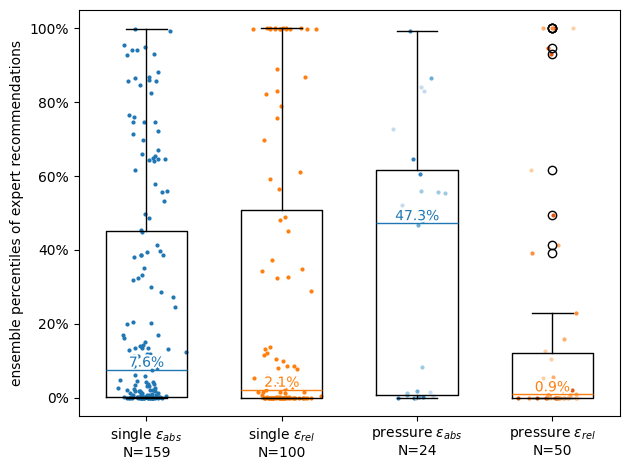

In [6]:
fig, ax = plt.subplots(layout="tight")

rng = np.random.default_rng(seed=42)

sabs = [
    q.absolute_percentile
    for v, q in single_expert.items()
    if not np.isnan(q.absolute_percentile)
]
srel = [
    q.relative_percentile
    for v, q in single_expert.items()
    if not np.isnan(q.relative_percentile)
]

b1 = ax.boxplot(sabs, positions=[0.0], medianprops={"color": "tab:blue"})
ax.scatter(rng.normal(loc=0.0, scale=0.025, size=len(sabs)), sabs, s=4, c="tab:blue")
ax.text(
    0.0,
    np.median(sabs),
    f"{np.format_float_positional(100 * np.median(sabs), precision=1, min_digits=1)}%",
    ha="center",
    va="bottom",
    color=b1["medians"][0].get_color(),
    path_effects=[mpe.withStroke(linewidth=3, foreground="white")],
)

b2 = ax.boxplot(srel, positions=[0.25], medianprops={"color": "tab:orange"})
ax.scatter(rng.normal(loc=0.25, scale=0.025, size=len(srel)), srel, s=4, c="tab:orange")
ax.text(
    0.25,
    np.median(srel),
    f"{np.format_float_positional(100 * np.median(srel), precision=1, min_digits=1)}%",
    ha="center",
    va="bottom",
    color=b2["medians"][0].get_color(),
    path_effects=[mpe.withStroke(linewidth=3, foreground="white")],
)

pabs = [
    q.absolute_percentile
    for p, vq in pressure_expert.items()
    for v, q in vq.items()
    if not np.isnan(q.absolute_percentile)
]
prel = [
    q.relative_percentile
    for p, vq in pressure_expert.items()
    for v, q in vq.items()
    if not np.isnan(q.relative_percentile)
]

ppabs = [
    p
    for p, vq in pressure_expert.items()
    for v, q in vq.items()
    if not np.isnan(q.absolute_percentile)
]
pprel = [
    p
    for p, vq in pressure_expert.items()
    for v, q in vq.items()
    if not np.isnan(q.relative_percentile)
]

tab20c = mpl.cm.tab20c.colors

b3 = ax.boxplot(pabs, positions=[0.5], medianprops={"color": "tab:blue"})
ax.scatter(
    rng.normal(
        loc=0.5, scale=0.025, size=np.count_nonzero(np.array(ppabs) == "50.0hPa")
    ),
    np.array(pabs)[np.array(ppabs) == "50.0hPa"],
    s=4,
    color=tab20c[0],
)
ax.scatter(
    rng.normal(
        loc=0.5, scale=0.025, size=np.count_nonzero(np.array(ppabs) == "500.0hPa")
    ),
    np.array(pabs)[np.array(ppabs) == "500.0hPa"],
    s=4,
    color=tab20c[1],
)
ax.scatter(
    rng.normal(
        loc=0.5, scale=0.025, size=np.count_nonzero(np.array(ppabs) == "850.0hPa")
    ),
    np.array(pabs)[np.array(ppabs) == "850.0hPa"],
    s=4,
    color=tab20c[2],
)
ax.scatter(
    rng.normal(
        loc=0.5, scale=0.025, size=np.count_nonzero(np.array(ppabs) == "1000.0hPa")
    ),
    np.array(pabs)[np.array(ppabs) == "1000.0hPa"],
    s=4,
    color=tab20c[3],
)
ax.text(
    0.5,
    np.median(pabs),
    f"{np.format_float_positional(100 * np.median(pabs), precision=1, min_digits=1)}%",
    ha="center",
    va="bottom",
    color=b3["medians"][0].get_color(),
    path_effects=[mpe.withStroke(linewidth=3, foreground="white")],
)

b4 = ax.boxplot(prel, positions=[0.75], medianprops={"color": "tab:orange"})
ax.scatter(
    rng.normal(
        loc=0.75, scale=0.025, size=np.count_nonzero(np.array(pprel) == "50.0hPa")
    ),
    np.array(prel)[np.array(pprel) == "50.0hPa"],
    s=4,
    color=tab20c[4],
)
ax.scatter(
    rng.normal(
        loc=0.75, scale=0.025, size=np.count_nonzero(np.array(pprel) == "500.0hPa")
    ),
    np.array(prel)[np.array(pprel) == "500.0hPa"],
    s=4,
    color=tab20c[5],
)
ax.scatter(
    rng.normal(
        loc=0.75, scale=0.025, size=np.count_nonzero(np.array(pprel) == "850.0hPa")
    ),
    np.array(prel)[np.array(pprel) == "850.0hPa"],
    s=4,
    color=tab20c[6],
)
ax.scatter(
    rng.normal(
        loc=0.75, scale=0.025, size=np.count_nonzero(np.array(pprel) == "1000.0hPa")
    ),
    np.array(prel)[np.array(pprel) == "1000.0hPa"],
    s=4,
    color=tab20c[7],
)

ax.text(
    0.75,
    np.median(prel),
    f"{np.format_float_positional(100 * np.median(prel), precision=1, min_digits=1)}%",
    ha="center",
    va="bottom",
    color=b4["medians"][0].get_color(),
    path_effects=[mpe.withStroke(linewidth=3, foreground="white")],
)

ax.set_xticks([0.0, 0.25, 0.5, 0.75])
ax.set_xticklabels(
    [
        f"single $\\epsilon_{{abs}}$\nN={len(sabs)}",
        f"single $\\epsilon_{{rel}}$\nN={len(srel)}",
        f"pressure $\\epsilon_{{abs}}$\nN={len(pabs)}",
        f"pressure $\\epsilon_{{rel}}$\nN={len(prel)}",
    ]
)
ax.set_xlim(-0.125, 0.875)
ax.set_ylabel("ensemble percentiles of expert recommendations")
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))

plt.tight_layout()

plt.show()
fig.savefig(plots / "boxplot.pdf")

In [7]:
single_range = {}
for _, (name, _level, *rest) in pd.read_csv("range-single.csv").iterrows():
    single_range[name] = RangeBounds(*rest)

In [8]:
from compression_recommendations import Recommendations
from compression_recommendations.requirements.error_bounds.max import (
    MaxPointwiseAbsoluteErrorBoundRequirement,
    MaxPointwiseQuadraticErrorBoundRequirement,
    MaxPointwiseRangeRelativeErrorBoundRequirement,
    MaxPointwiseRelativeErrorBoundRequirement,
)

In [9]:
with Path("recommendations", "grib-linear-packing.yaml").open("r") as f:
    grib_recommendations = Recommendations.load(f)

In [10]:
single_grib = {}
for key in single_range:
    (requirement,) = grib_recommendations.search(
        markers={"cf-short-name": key, "level-kind": "single"}
    )
    assert isinstance(requirement, MaxPointwiseRangeRelativeErrorBoundRequirement)
    single_grib[key] = requirement.value

In [11]:
with Path("recommendations", "ensemble-spread.yaml").open("r") as f:
    ensemble_recommendations = Recommendations.load(f)

In [12]:
single_ensemble = {}
for key in single_range:
    percentile = [0.0, 0.001, 0.01, 0.05]
    absolute = []
    for p in percentile:
        (requirement,) = ensemble_recommendations.search(
            markers={
                "cf-short-name": key,
                "level-kind": "single",
                "tags": f"absolute,{p * 100}%",
            }
        )
        assert isinstance(requirement, MaxPointwiseAbsoluteErrorBoundRequirement), repr(
            requirement
        )
        absolute.append(requirement.value)
    relative = []
    for p in percentile:
        (requirement,) = ensemble_recommendations.search(
            markers={
                "cf-short-name": key,
                "level-kind": "single",
                "tags": f"relative,{p * 100}%",
            }
        )
        assert isinstance(requirement, MaxPointwiseRelativeErrorBoundRequirement), repr(
            requirement
        )
        relative.append(requirement.value)
    quadratic = []
    for p in percentile:
        (requirement,) = ensemble_recommendations.search(
            markers={
                "cf-short-name": key,
                "level-kind": "single",
                "tags": f"quadratic,{p * 100}%",
            }
        )
        assert isinstance(requirement, MaxPointwiseQuadraticErrorBoundRequirement), (
            repr(requirement)
        )
        quadratic.append(requirement.value)
    single_ensemble[key] = EnsembleSpreadBounds(
        percentile=percentile, absolute=absolute, relative=relative, quadratic=quadratic
    )

In [13]:
with Path("recommendations", "bit-information.yaml").open("r") as f:
    bit_information_recommendations = Recommendations.load(f)

In [14]:
single_bit_information = {}
for key, single_range_of_key in single_range.items():
    percentile = [1.0, 0.999, 0.99, 0.95]
    relative = []
    for p in percentile:
        (requirement,) = bit_information_recommendations.search(
            markers={
                "cf-short-name": key,
                "level-kind": "single",
                "tags": f"relative,{p * 100}%",
            }
        )
        assert isinstance(requirement, MaxPointwiseRelativeErrorBoundRequirement), repr(
            requirement
        )
        relative.append(requirement.value)
    absolute = [
        max(abs(single_range_of_key.min), abs(single_range_of_key.max)) * r
        for r in relative
    ]
    single_bit_information[key] = BitInformationBounds(
        percentile=percentile, absolute=absolute, relative=relative
    )

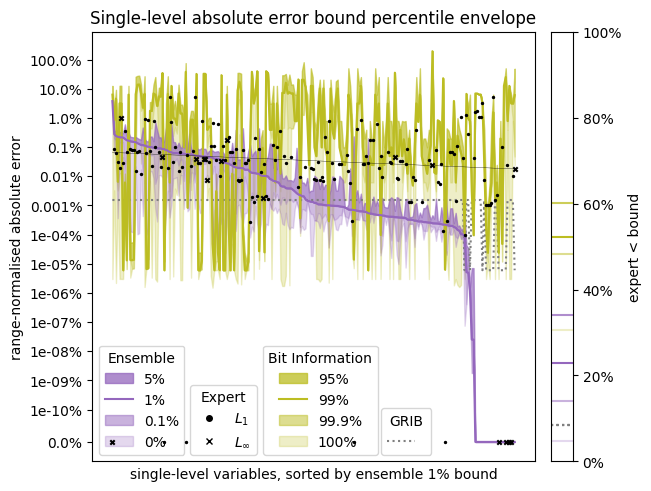

In [15]:
fig, (ax, axr) = plt.subplots(
    1, 2, width_ratios=[20, 1], gridspec_kw={"wspace": 0.05}, layout="constrained"
)

ax.set_title("Single-level absolute error bound percentile envelope")
ax.set_ylabel("range-normalised absolute error")

scores = {
    v: (
        0.0
        if single_range[v].max == single_range[v].min
        else (e.absolute[2] / (single_range[v].max - single_range[v].min))
    )
    for v, e in single_ensemble.items()
}
v_sorted = sorted(scores.keys(), key=lambda k: scores[k], reverse=True)

ax.plot(
    [single_grib[v] for v in v_sorted],
    color="tab:gray",
    ls=":",
)

expert_xs = []
expert_ys = []
expert_pointwise = []
for i, v in enumerate(v_sorted):
    expert_xs.append(i)
    expert_ys.append(
        0.0
        if single_range[v].max == single_range[v].min
        else (
            single_expert[v].absolute_value
            / (single_range[v].max - single_range[v].min)
        )
    )
    expert_pointwise.append(single_expert[v].absolute_kind == "max")
expert_pointwise = np.array(expert_pointwise)
ax.scatter(
    np.array(expert_xs)[expert_pointwise],
    np.array(expert_ys)[expert_pointwise],
    s=10,
    marker="x",
    c="black",
    label="expert",
    zorder=9,
)
ax.scatter(
    np.array(expert_xs)[~expert_pointwise],
    np.array(expert_ys)[~expert_pointwise],
    s=2,
    marker="o",
    c="black",
    label="expert",
    zorder=9,
)

expert_fit = Polynomial.fit(
    np.array(expert_xs)[np.array(expert_ys) > 0],
    np.log(np.array(expert_ys)[np.array(expert_ys) > 0]),
    deg=1,
)
ax.plot(expert_xs, np.exp(expert_fit(expert_xs)), zorder=11, lw=0.25, c="black")

ax.fill_between(
    range(len(v_sorted)),
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_bit_information[v].absolute[0]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_bit_information[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    alpha=0.25,
    color="tab:olive",
    label="100%",
)
ax.fill_between(
    range(len(v_sorted)),
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_bit_information[v].absolute[1]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_bit_information[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    alpha=0.25,
    color="tab:olive",
    label="99.9%",
)
ax.plot(
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_bit_information[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    color="tab:olive",
    label="99%",
)
ax.fill_between(
    range(len(v_sorted)),
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_bit_information[v].absolute[3]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_bit_information[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    alpha=0.66,
    color="tab:olive",
    label="95%",
)

ax.fill_between(
    range(len(v_sorted)),
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[0]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    alpha=0.25,
    color="tab:purple",
    label="0%",
)
ax.fill_between(
    range(len(v_sorted)),
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[1]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    alpha=0.25,
    color="tab:purple",
    label="0.1%",
)
ax.plot(
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    color="tab:purple",
    label="1%",
)
ax.fill_between(
    range(len(v_sorted)),
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[3]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    alpha=0.66,
    color="tab:purple",
    label="5%",
)

ax.set_yscale("symlog", linthresh=1e-12)

l1 = ax.legend(
    handles=[
        mpl.patches.Patch(color="tab:purple", alpha=0.75, label="5%"),
        mpl.lines.Line2D([0], [0], color="tab:purple", label="1%"),
        mpl.patches.Patch(color="tab:purple", alpha=0.5, label="0.1%"),
        mpl.patches.Patch(color="tab:purple", alpha=0.25, label="0%"),
    ],
    ncol=1,
    loc="lower left",
    title="Ensemble",
)
l2 = ax.legend(
    handles=[
        mpl.lines.Line2D(
            [0],
            [0],
            markersize=4,
            marker="o",
            color="none",
            markerfacecolor="black",
            markeredgecolor="black",
            label="$L_1$",
        ),
        mpl.lines.Line2D(
            [0],
            [0],
            markersize=4,
            marker="x",
            color="none",
            markerfacecolor="black",
            markeredgecolor="black",
            label=r"$L_{\infty}$",
        ),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.205, 0, 1, 1),
    title="Expert",
)
l3 = ax.legend(
    handles=[
        mpl.patches.Patch(color="tab:olive", alpha=0.75, label="95%"),
        mpl.lines.Line2D([0], [0], color="tab:olive", label="99%"),
        mpl.patches.Patch(color="tab:olive", alpha=0.5, label="99.9%"),
        mpl.patches.Patch(color="tab:olive", alpha=0.25, label="100%"),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.37, 0, 1, 1),
    title="Bit Information",
)
ax.legend(
    handles=[
        mpl.lines.Line2D([0], [0], color="tab:gray", ls=":"),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.6375, 0, 1, 1),
    title="GRIB",
)
ax.add_artist(l1)
ax.add_artist(l2)
ax.add_artist(l3)

ax.set_xticks([])
ax.set_xlabel("single-level variables, sorted by ensemble 1% bound")
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(
        lambda x, pos=None: (
            f"{np.round(x * 100, 10)}%"
            if x == 0 or x >= 1e-5
            else f"{np.round(x * 100, 10):.0e}%"
        )
    )
)

axr.set_xticks([])
axr.yaxis.tick_right()
axr.yaxis.set_label_position("right")
axr.set_ylabel("expert < bound")
axr.yaxis.set_major_formatter(mtick.PercentFormatter(1))
axr.set_ylim(0, 1)

for i, p in enumerate(single_ensemble["u10"].percentile):
    count = 0
    for v, single_expert_v in single_expert.items():
        count += single_expert_v.absolute_value < single_ensemble[v].absolute[i]
    axr.axhline(
        count / len(single_expert), c="tab:purple", alpha=[0.25, 0.5, 1.0, 0.75][i]
    )

for i, p in enumerate(single_ensemble["u10"].percentile):
    count = 0
    for v, single_expert_v in single_expert.items():
        count += single_expert_v.absolute_value < single_bit_information[v].absolute[i]
    axr.axhline(
        count / len(single_expert), c="tab:olive", alpha=[0.25, 0.5, 1.0, 0.75][i]
    )

for i, p in enumerate(single_ensemble["u10"].percentile):
    count = 0
    for v, single_expert_v in single_expert.items():
        count += single_expert_v.absolute_value < (
            single_grib[v] * (single_range[v].max - single_range[v].min)
        )
    axr.axhline(count / len(single_expert), c="tab:gray", ls=":")

plt.show()
fig.savefig(plots / "single-absolute.pdf")

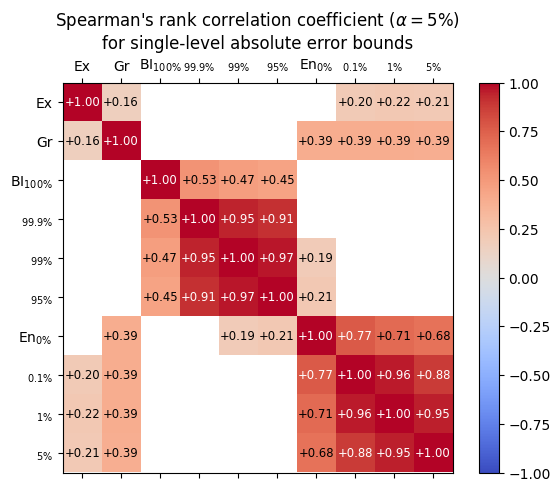

In [16]:
observations = (
    [expert_ys]
    + [[single_grib[v] for v in v_sorted]]
    + [
        [
            (
                0.0
                if single_range[v].max == single_range[v].min
                else (
                    single_bit_information[v].absolute[i]
                    / (single_range[v].max - single_range[v].min)
                )
            )
            for v in v_sorted
        ]
        for i in range(4)
    ]
    + [
        [
            (
                0.0
                if single_range[v].max == single_range[v].min
                else (
                    single_ensemble[v].absolute[i]
                    / (single_range[v].max - single_range[v].min)
                )
            )
            for v in v_sorted
        ]
        for i in range(4)
    ]
)

spearmanr = stats.spearmanr(observations, axis=1, nan_policy="omit")

fig, ax = plt.subplots(layout="constrained")

alpha = 0.05

m = ax.matshow(
    np.where(spearmanr.pvalue < alpha, spearmanr.statistic, np.nan),
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)

X, Y = np.meshgrid(np.arange(len(observations)), np.arange(len(observations)))
for x, y in zip(X.flatten(), Y.flatten()):
    if spearmanr.pvalue[x, y] < alpha:
        ax.text(
            x,
            y,
            f"{np.format_float_positional(spearmanr.statistic[x, y], precision=2, min_digits=2, sign=True)}",
            va="center",
            ha="center",
            fontsize="small",
            color="white" if np.abs(spearmanr.statistic[x, y]) > 0.75 else "black",
        )

ax.set_title(
    r"Spearman's rank correlation coefficient ($\alpha = 5\%$)"
    + "\nfor single-level absolute error bounds"
)

ax.set_xticks(range(len(observations)))
ax.set_xticklabels(
    [
        "Ex",
        "Gr",
        r"BI$_{100\%}$",
        r"$_{99.9\%}$",
        r"$_{99\%}$",
        r"$_{95\%}$",
        r"En$_{0\%}$",
        r"$_{0.1\%}$",
        r"$_{1\%}$",
        r"$_{5\%}$",
    ]
)

ax.set_yticks(range(len(observations)))
ax.set_yticklabels(
    [
        "Ex",
        "Gr",
        r"BI$_{100\%}$",
        r"$_{99.9\%}$",
        r"$_{99\%}$",
        r"$_{95\%}$",
        r"En$_{0\%}$",
        r"$_{0.1\%}$",
        r"$_{1\%}$",
        r"$_{5\%}$",
    ]
)

fig.colorbar(m)

plt.show()
fig.savefig(plots / "single-absolute-rank.pdf")

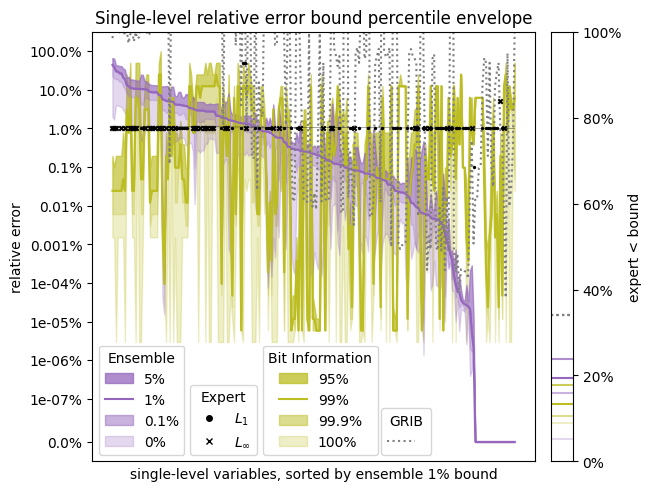

In [17]:
fig, (ax, axr) = plt.subplots(
    1, 2, width_ratios=[20, 1], gridspec_kw={"wspace": 0.05}, layout="constrained"
)

ax.set_title("Single-level relative error bound percentile envelope")
ax.set_ylabel("relative error")

scores = {v: e.relative[2] for v, e in single_ensemble.items()}
v_sorted = sorted(scores.keys(), key=lambda k: scores[k], reverse=True)

expert_xs = []
expert_ys = []
expert_pointwise = []
for i, v in enumerate(v_sorted):
    expert_xs.append(i)
    expert_ys.append(single_expert[v].relative_value)
    expert_pointwise.append(single_expert[v].absolute_kind == "max")
expert_pointwise = np.array(expert_pointwise)
ax.scatter(
    np.array(expert_xs)[expert_pointwise],
    np.array(expert_ys)[expert_pointwise],
    s=10,
    marker="x",
    c="black",
    label="expert",
    zorder=9,
)
ax.scatter(
    np.array(expert_xs)[~expert_pointwise],
    np.array(expert_ys)[~expert_pointwise],
    s=2,
    marker="o",
    c="black",
    label="expert",
    zorder=9,
)

expert_fit = Polynomial.fit(
    np.array(expert_xs)[np.array(expert_ys) > 0],
    np.log(np.array(expert_ys)[np.array(expert_ys) > 0]),
    deg=1,
)
ax.plot(expert_xs, np.exp(expert_fit(expert_xs)), zorder=11, lw=0.25, c="black")

ax.fill_between(
    range(len(v_sorted)),
    [single_bit_information[v].relative[0] for v in v_sorted],
    [single_bit_information[v].relative[2] for v in v_sorted],
    alpha=0.25,
    color="tab:olive",
    label="100%",
)
ax.fill_between(
    range(len(v_sorted)),
    [single_bit_information[v].relative[1] for v in v_sorted],
    [single_bit_information[v].relative[2] for v in v_sorted],
    alpha=0.25,
    color="tab:olive",
    label="99.9%",
)
ax.plot(
    [single_bit_information[v].relative[2] for v in v_sorted],
    color="tab:olive",
    label="99%",
)
ax.fill_between(
    range(len(v_sorted)),
    [single_bit_information[v].relative[3] for v in v_sorted],
    [single_bit_information[v].relative[2] for v in v_sorted],
    alpha=0.66,
    color="tab:olive",
    label="95%",
)

ax.fill_between(
    range(len(v_sorted)),
    [single_ensemble[v].relative[0] for v in v_sorted],
    [single_ensemble[v].relative[2] for v in v_sorted],
    alpha=0.25,
    color="tab:purple",
    label="0%",
)
ax.fill_between(
    range(len(v_sorted)),
    [single_ensemble[v].relative[1] for v in v_sorted],
    [single_ensemble[v].relative[2] for v in v_sorted],
    alpha=0.25,
    color="tab:purple",
    label="0.1%",
)
ax.plot(
    [single_ensemble[v].relative[2] for v in v_sorted], color="tab:purple", label="1%"
)
ax.fill_between(
    range(len(v_sorted)),
    [single_ensemble[v].relative[3] for v in v_sorted],
    [single_ensemble[v].relative[2] for v in v_sorted],
    alpha=0.66,
    color="tab:purple",
    label="5%",
)

ax.set_yscale("symlog", linthresh=1e-9)

ylim = ax.get_ylim()

ax.plot(
    [
        single_grib[v]
        * (single_range[v].max - single_range[v].min)
        / single_range[v].min_abs
        for v in v_sorted
    ],
    color="tab:gray",
    ls=":",
)

ax.set_ylim(*ylim)

l1 = ax.legend(
    handles=[
        mpl.patches.Patch(color="tab:purple", alpha=0.75, label="5%"),
        mpl.lines.Line2D([0], [0], color="tab:purple", label="1%"),
        mpl.patches.Patch(color="tab:purple", alpha=0.5, label="0.1%"),
        mpl.patches.Patch(color="tab:purple", alpha=0.25, label="0%"),
    ],
    ncol=1,
    loc="lower left",
    title="Ensemble",
)
l2 = ax.legend(
    handles=[
        mpl.lines.Line2D(
            [0],
            [0],
            markersize=4,
            marker="o",
            color="none",
            markerfacecolor="black",
            markeredgecolor="black",
            label="$L_1$",
        ),
        mpl.lines.Line2D(
            [0],
            [0],
            markersize=4,
            marker="x",
            color="none",
            markerfacecolor="black",
            markeredgecolor="black",
            label=r"$L_{\infty}$",
        ),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.205, 0, 1, 1),
    title="Expert",
)
l3 = ax.legend(
    handles=[
        mpl.patches.Patch(color="tab:olive", alpha=0.75, label="95%"),
        mpl.lines.Line2D([0], [0], color="tab:olive", label="99%"),
        mpl.patches.Patch(color="tab:olive", alpha=0.5, label="99.9%"),
        mpl.patches.Patch(color="tab:olive", alpha=0.25, label="100%"),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.37, 0, 1, 1),
    title="Bit Information",
)
ax.legend(
    handles=[
        mpl.lines.Line2D([0], [0], color="tab:gray", ls=":"),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.6375, 0, 1, 1),
    title="GRIB",
)
ax.add_artist(l1)
ax.add_artist(l2)
ax.add_artist(l3)

ax.set_xticks([])
ax.set_xlabel("single-level variables, sorted by ensemble 1% bound")
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(
        lambda x, pos=None: (
            f"{np.round(x * 100, 7)}%"
            if x == 0 or x >= 1e-5
            else f"{np.round(x * 100, 7):.0e}%"
        )
    )
)

axr.set_xticks([])
axr.yaxis.tick_right()
axr.yaxis.set_label_position("right")
axr.set_ylabel("expert < bound")
axr.yaxis.set_major_formatter(mtick.PercentFormatter(1))
axr.set_ylim(0, 1)

for i, p in enumerate(single_ensemble["u10"].percentile):
    count = 0
    for v, single_expert_v in single_expert.items():
        count += single_expert_v.relative_value < single_ensemble[v].relative[i]
    axr.axhline(
        count / len(single_expert), c="tab:purple", alpha=[0.25, 0.5, 1.0, 0.75][i]
    )

for i, p in enumerate(single_ensemble["u10"].percentile):
    count = 0
    for v, single_expert_v in single_expert.items():
        count += single_expert_v.relative_value < single_bit_information[v].relative[i]
    axr.axhline(
        count / len(single_expert), c="tab:olive", alpha=[0.25, 0.5, 1.0, 0.75][i]
    )

for i, p in enumerate(single_ensemble["u10"].percentile):
    count = 0
    for v, single_expert_v in single_expert.items():
        count += single_expert_v.relative_value < (
            single_grib[v]
            * (single_range[v].max - single_range[v].min)
            / single_range[v].min_abs
        )
    axr.axhline(count / len(single_expert), c="tab:gray", ls=":")

plt.show()
fig.savefig(plots / "single-relative.pdf")

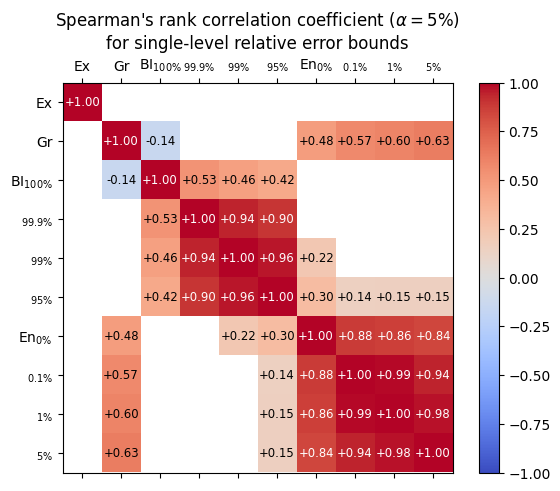

In [18]:
observations = (
    [expert_ys]
    + [
        [
            single_grib[v]
            * (single_range[v].max - single_range[v].min)
            / single_range[v].min_abs
            for v in v_sorted
        ]
    ]
    + [[single_bit_information[v].relative[i] for v in v_sorted] for i in range(4)]
    + [[single_ensemble[v].relative[i] for v in v_sorted] for i in range(4)]
)

spearmanr = stats.spearmanr(observations, axis=1, nan_policy="omit")

fig, ax = plt.subplots(layout="constrained")

alpha = 0.05

m = ax.matshow(
    np.where(spearmanr.pvalue < alpha, spearmanr.statistic, np.nan),
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)

X, Y = np.meshgrid(np.arange(len(observations)), np.arange(len(observations)))
for x, y in zip(X.flatten(), Y.flatten()):
    if spearmanr.pvalue[x, y] < alpha:
        ax.text(
            x,
            y,
            f"{np.format_float_positional(spearmanr.statistic[x, y], precision=2, min_digits=2, sign=True)}",
            va="center",
            ha="center",
            fontsize="small",
            color="white" if np.abs(spearmanr.statistic[x, y]) > 0.75 else "black",
        )

ax.set_title(
    r"Spearman's rank correlation coefficient ($\alpha = 5\%$)"
    + "\nfor single-level relative error bounds"
)

ax.set_xticks(range(len(observations)))
ax.set_xticklabels(
    [
        "Ex",
        "Gr",
        r"BI$_{100\%}$",
        r"$_{99.9\%}$",
        r"$_{99\%}$",
        r"$_{95\%}$",
        r"En$_{0\%}$",
        r"$_{0.1\%}$",
        r"$_{1\%}$",
        r"$_{5\%}$",
    ]
)

ax.set_yticks(range(len(observations)))
ax.set_yticklabels(
    [
        "Ex",
        "Gr",
        r"BI$_{100\%}$",
        r"$_{99.9\%}$",
        r"$_{99\%}$",
        r"$_{95\%}$",
        r"En$_{0\%}$",
        r"$_{0.1\%}$",
        r"$_{1\%}$",
        r"$_{5\%}$",
    ]
)

fig.colorbar(m)

plt.show()
fig.savefig(plots / "single-relative-rank.pdf")

In [19]:
pressure_range = defaultdict(dict)
for _, (name, level, *rest) in pd.read_csv("range-pressure.csv").iterrows():
    pressure_range[level][name] = RangeBounds(*rest)
pressure_range = dict(pressure_range)

In [20]:
pressure_grib = {}
for pressure in pressure_range:
    pressure_grib[pressure] = {}
    for key in pressure_range[pressure]:
        (requirement,) = grib_recommendations.search(
            markers={
                "cf-short-name": key,
                "level-kind": "pressure",
                "level-value": float(pressure.replace("hPa", "")),
            }
        )
        assert isinstance(requirement, MaxPointwiseRangeRelativeErrorBoundRequirement)
        pressure_grib[pressure][key] = requirement.value

In [21]:
pressure_ensemble = {}
for pressure in pressure_range:
    pressure_ensemble[pressure] = {}
    for key in pressure_range[pressure]:
        percentile = [0.0, 0.001, 0.01, 0.05]
        absolute = []
        for p in percentile:
            (requirement,) = ensemble_recommendations.search(
                markers={
                    "cf-short-name": key,
                    "level-kind": "pressure",
                    "level-value": float(pressure.replace("hPa", "")),
                    "tags": f"absolute,{p * 100}%",
                }
            )
            assert isinstance(requirement, MaxPointwiseAbsoluteErrorBoundRequirement), (
                repr(requirement)
            )
            absolute.append(requirement.value)
        relative = []
        for p in percentile:
            (requirement,) = ensemble_recommendations.search(
                markers={
                    "cf-short-name": key,
                    "level-kind": "pressure",
                    "level-value": float(pressure.replace("hPa", "")),
                    "tags": f"relative,{p * 100}%",
                }
            )
            assert isinstance(requirement, MaxPointwiseRelativeErrorBoundRequirement), (
                repr(requirement)
            )
            relative.append(requirement.value)
        quadratic = []
        for p in percentile:
            (requirement,) = ensemble_recommendations.search(
                markers={
                    "cf-short-name": key,
                    "level-kind": "pressure",
                    "level-value": float(pressure.replace("hPa", "")),
                    "tags": f"quadratic,{p * 100}%",
                }
            )
            assert isinstance(
                requirement, MaxPointwiseQuadraticErrorBoundRequirement
            ), repr(requirement)
            quadratic.append(requirement.value)
        pressure_ensemble[pressure][key] = EnsembleSpreadBounds(
            percentile=percentile,
            absolute=absolute,
            relative=relative,
            quadratic=quadratic,
        )

In [22]:
pressure_bit_information = {}
for pressure in pressure_range:
    pressure_bit_information[pressure] = {}
    for key in pressure_range[pressure]:
        percentile = [1.0, 0.999, 0.99, 0.95]
        relative = []
        for p in percentile:
            (requirement,) = bit_information_recommendations.search(
                markers={
                    "cf-short-name": key,
                    "level-kind": "pressure",
                    "level-value": float(pressure.replace("hPa", "")),
                    "tags": f"relative,{p * 100}%",
                }
            )
            assert isinstance(requirement, MaxPointwiseRelativeErrorBoundRequirement), (
                repr(requirement)
            )
            relative.append(requirement.value)
        absolute = [
            max(
                abs(pressure_range[pressure][key].min),
                abs(pressure_range[pressure][key].max),
            )
            * r
            for r in relative
        ]
        pressure_bit_information[pressure][key] = BitInformationBounds(
            percentile=percentile,
            absolute=absolute,
            relative=relative,
        )

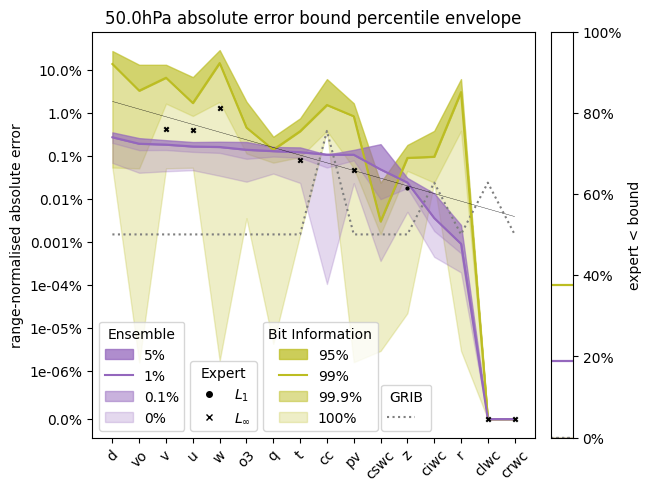

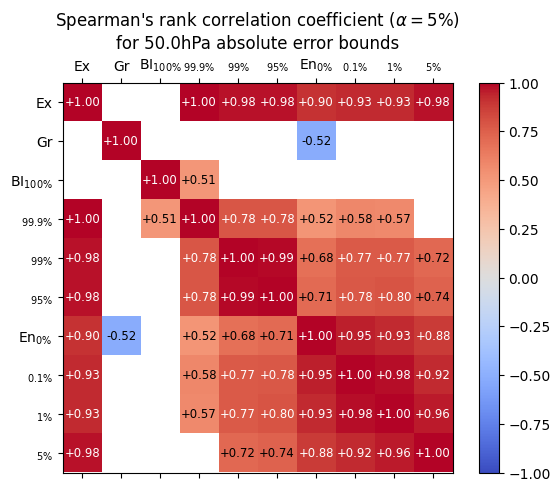

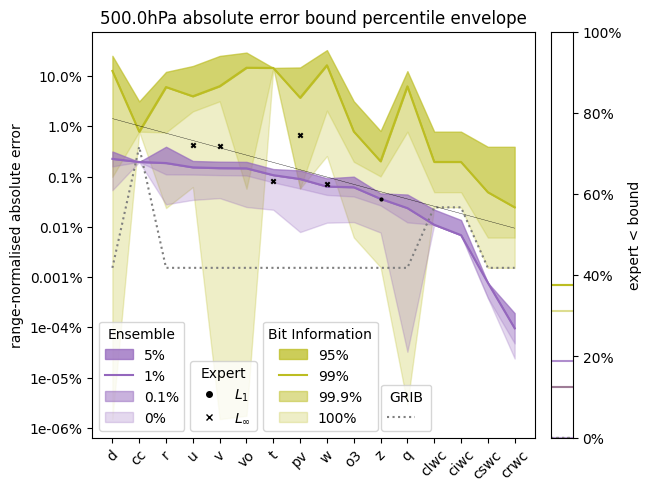

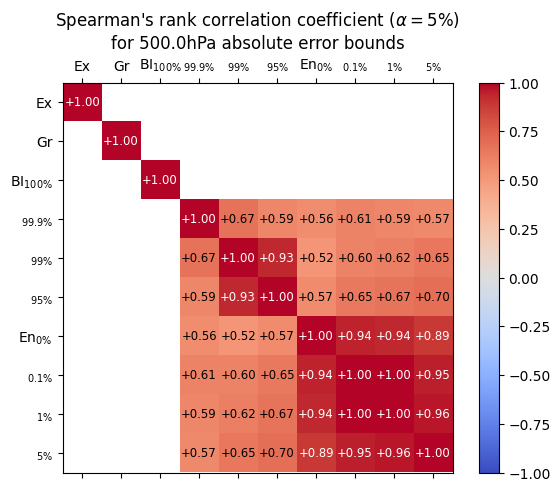

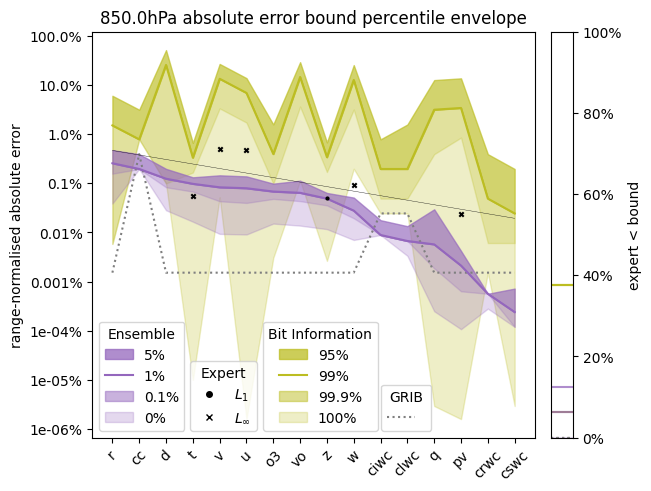

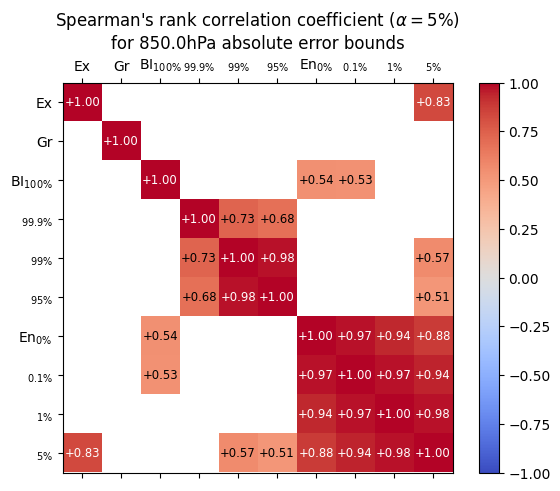

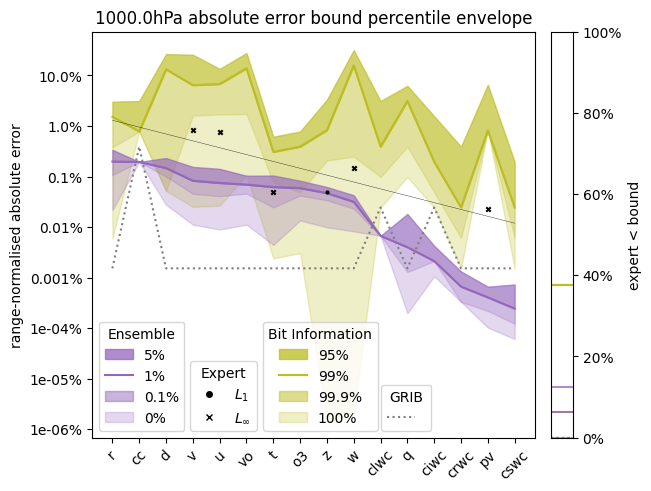

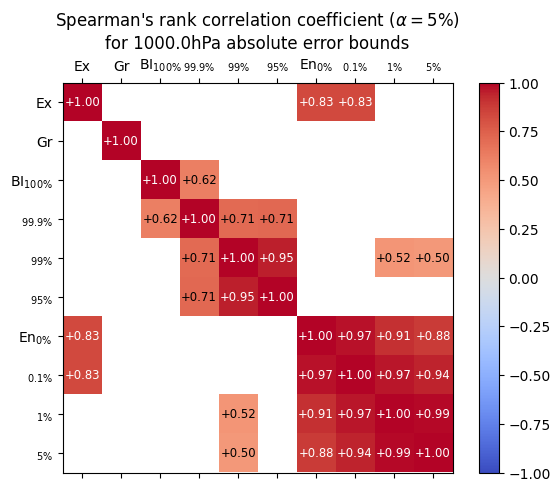

In [23]:
for p, pressure_ensemble_p in pressure_ensemble.items():
    fig, (ax, axr) = plt.subplots(
        1, 2, width_ratios=[20, 1], gridspec_kw={"wspace": 0.05}, layout="constrained"
    )

    ax.set_title(f"{p} absolute error bound percentile envelope")
    ax.set_ylabel("range-normalised absolute error")

    scores = {
        v: (
            0.0
            if pressure_range[p][v].max == pressure_range[p][v].min
            else (e.absolute[2] / (pressure_range[p][v].max - pressure_range[p][v].min))
        )
        for v, e in pressure_ensemble_p.items()
    }
    v_sorted = sorted(scores.keys(), key=lambda k: scores[k], reverse=True)

    ax.plot(
        [pressure_grib[p][v] for v in v_sorted],
        color="tab:gray",
        ls=":",
    )

    expert_xs = []
    expert_ys = []
    expert_pointwise = []
    for i, v in enumerate(v_sorted):
        expert_xs.append(i)
        expert_ys.append(
            0.0
            if pressure_range[p][v].max == pressure_range[p][v].min
            else (
                pressure_expert[p][v].absolute_value
                / (pressure_range[p][v].max - pressure_range[p][v].min)
            )
        )
        expert_pointwise.append(pressure_expert[p][v].absolute_kind == "max")
    expert_pointwise = np.array(expert_pointwise)
    ax.scatter(
        np.array(expert_xs)[expert_pointwise],
        np.array(expert_ys)[expert_pointwise],
        s=10,
        marker="x",
        c="black",
        label="expert",
        zorder=9,
    )
    ax.scatter(
        np.array(expert_xs)[~expert_pointwise],
        np.array(expert_ys)[~expert_pointwise],
        s=4,
        marker="o",
        c="black",
        label="expert",
        zorder=9,
    )

    expert_fit = Polynomial.fit(
        np.array(expert_xs)[np.array(expert_ys) > 0],
        np.log(np.array(expert_ys)[np.array(expert_ys) > 0]),
        deg=1,
    )
    ax.plot(expert_xs, np.exp(expert_fit(expert_xs)), zorder=11, lw=0.25, c="black")

    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].absolute[0]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.25,
        color="tab:olive",
        label="100%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].absolute[1]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.25,
        color="tab:olive",
        label="99.9%",
    )
    ax.plot(
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        color="tab:olive",
        label="99%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].absolute[3]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.66,
        color="tab:olive",
        label="95%",
    )

    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble_p[v].absolute[0]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble_p[v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.25,
        color="tab:purple",
        label="0%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble_p[v].absolute[1]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble_p[v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.25,
        color="tab:purple",
        label="0.1%",
    )
    ax.plot(
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble_p[v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        color="tab:purple",
        label="1%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble_p[v].absolute[3]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble_p[v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.66,
        color="tab:purple",
        label="5%",
    )

    ax.set_yscale("symlog", linthresh=1e-8)

    l1 = ax.legend(
        handles=[
            mpl.patches.Patch(color="tab:purple", alpha=0.75, label="5%"),
            mpl.lines.Line2D([0], [0], color="tab:purple", label="1%"),
            mpl.patches.Patch(color="tab:purple", alpha=0.5, label="0.1%"),
            mpl.patches.Patch(color="tab:purple", alpha=0.25, label="0%"),
        ],
        ncol=1,
        loc="lower left",
        title="Ensemble",
    )
    l2 = ax.legend(
        handles=[
            mpl.lines.Line2D(
                [0],
                [0],
                markersize=4,
                marker="o",
                color="none",
                markerfacecolor="black",
                markeredgecolor="black",
                label="$L_1$",
            ),
            mpl.lines.Line2D(
                [0],
                [0],
                markersize=4,
                marker="x",
                color="none",
                markerfacecolor="black",
                markeredgecolor="black",
                label=r"$L_{\infty}$",
            ),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.205, 0, 1, 1),
        title="Expert",
    )
    l3 = ax.legend(
        handles=[
            mpl.patches.Patch(color="tab:olive", alpha=0.75, label="95%"),
            mpl.lines.Line2D([0], [0], color="tab:olive", label="99%"),
            mpl.patches.Patch(color="tab:olive", alpha=0.5, label="99.9%"),
            mpl.patches.Patch(color="tab:olive", alpha=0.25, label="100%"),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.37, 0, 1, 1),
        title="Bit Information",
    )
    ax.legend(
        handles=[
            mpl.lines.Line2D([0], [0], color="tab:gray", ls=":"),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.6375, 0, 1, 1),
        title="GRIB",
    )
    ax.add_artist(l1)
    ax.add_artist(l2)
    ax.add_artist(l3)

    ax.set_xticks(range(len(v_sorted)))
    ax.set_xticklabels(v_sorted, rotation=45)
    # ax.set_xlabel("sorted by ensemble 1% bound")
    ax.yaxis.set_major_formatter(
        mtick.FuncFormatter(
            lambda x, pos=None: (
                f"{np.round(x * 100, 6)}%"
                if x == 0 or x >= 1e-5
                else f"{np.round(x * 100, 6):.0e}%"
            )
        )
    )

    axr.set_xticks([])
    axr.yaxis.tick_right()
    axr.yaxis.set_label_position("right")
    axr.set_ylabel("expert < bound")
    axr.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    axr.set_ylim(0, 1)

    for i, pt in enumerate(pressure_ensemble["1000.0hPa"]["u"].percentile):
        count = 0
        for v in pressure_expert[p]:
            count += (
                pressure_expert[p][v].absolute_value
                < pressure_ensemble_p[v].absolute[i]
            )
        axr.axhline(
            count / len(pressure_expert[p]),
            c="tab:purple",
            alpha=[0.25, 0.5, 1.0, 0.75][i],
        )

    for i, pt in enumerate(pressure_ensemble["1000.0hPa"]["u"].percentile):
        count = 0
        for v in pressure_expert[p]:
            count += (
                pressure_expert[p][v].absolute_value
                < pressure_bit_information[p][v].absolute[i]
            )
        axr.axhline(
            count / len(pressure_expert[p]),
            c="tab:olive",
            alpha=[0.25, 0.5, 1.0, 0.75][i],
        )

    for i, pt in enumerate(pressure_ensemble["1000.0hPa"]["u"].percentile):
        count = 0
        for v in pressure_expert[p]:
            count += pressure_expert[p][v].absolute_value < (
                pressure_grib[p][v]
                * (pressure_range[p][v].max - pressure_range[p][v].min)
            )
        axr.axhline(count / len(pressure_expert[p]), c="tab:gray", ls=":")

    plt.show()
    fig.savefig(plots / f"pressure-{p.replace(' ', '')}-absolute.pdf")

    observations = (
        [expert_ys]
        + [[pressure_grib[p][v] for v in v_sorted]]
        + [
            [
                (
                    0.0
                    if pressure_range[p][v].max == pressure_range[p][v].min
                    else (
                        pressure_bit_information[p][v].absolute[i]
                        / (pressure_range[p][v].max - pressure_range[p][v].min)
                    )
                )
                for v in v_sorted
            ]
            for i in range(4)
        ]
        + [
            [
                (
                    0.0
                    if pressure_range[p][v].max == pressure_range[p][v].min
                    else (
                        pressure_ensemble_p[v].absolute[i]
                        / (pressure_range[p][v].max - pressure_range[p][v].min)
                    )
                )
                for v in v_sorted
            ]
            for i in range(4)
        ]
    )

    spearmanr = stats.spearmanr(observations, axis=1, nan_policy="omit")

    fig, ax = plt.subplots(layout="constrained")

    alpha = 0.05

    m = ax.matshow(
        np.where(spearmanr.pvalue < alpha, spearmanr.statistic, np.nan),
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
    )

    X, Y = np.meshgrid(np.arange(len(observations)), np.arange(len(observations)))
    for x, y in zip(X.flatten(), Y.flatten()):
        if spearmanr.pvalue[x, y] < alpha:
            ax.text(
                x,
                y,
                f"{np.format_float_positional(spearmanr.statistic[x, y], precision=2, min_digits=2, sign=True)}",
                va="center",
                ha="center",
                fontsize="small",
                color="white" if np.abs(spearmanr.statistic[x, y]) > 0.75 else "black",
            )

    ax.set_title(
        r"Spearman's rank correlation coefficient ($\alpha = 5\%$)"
        + f"\nfor {p} absolute error bounds"
    )

    ax.set_xticks(range(len(observations)))
    ax.set_xticklabels(
        [
            "Ex",
            "Gr",
            r"BI$_{100\%}$",
            r"$_{99.9\%}$",
            r"$_{99\%}$",
            r"$_{95\%}$",
            r"En$_{0\%}$",
            r"$_{0.1\%}$",
            r"$_{1\%}$",
            r"$_{5\%}$",
        ]
    )

    ax.set_yticks(range(len(observations)))
    ax.set_yticklabels(
        [
            "Ex",
            "Gr",
            r"BI$_{100\%}$",
            r"$_{99.9\%}$",
            r"$_{99\%}$",
            r"$_{95\%}$",
            r"En$_{0\%}$",
            r"$_{0.1\%}$",
            r"$_{1\%}$",
            r"$_{5\%}$",
        ]
    )

    fig.colorbar(m)

    plt.show()
    fig.savefig(plots / f"pressure-{p.replace(' ', '')}-absolute-rank.pdf")

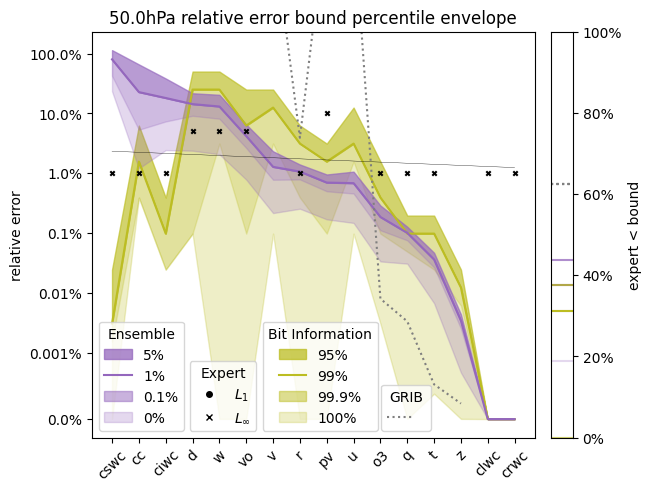

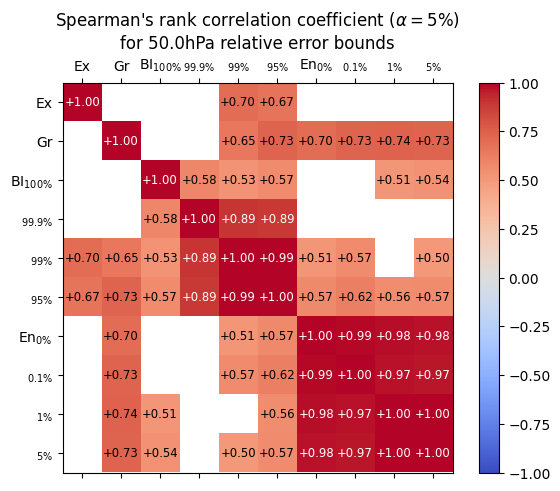

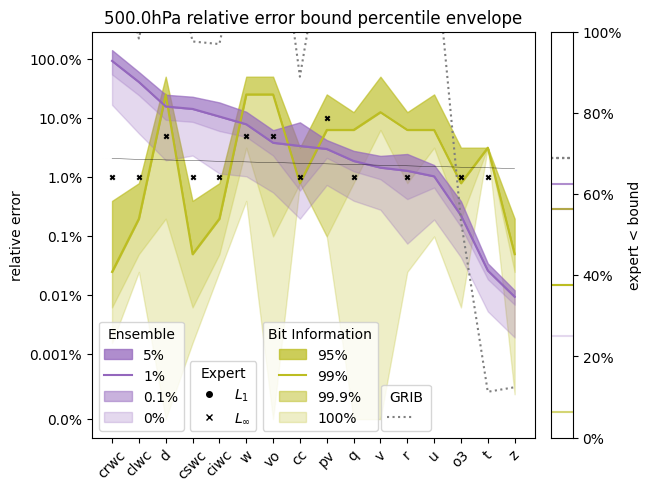

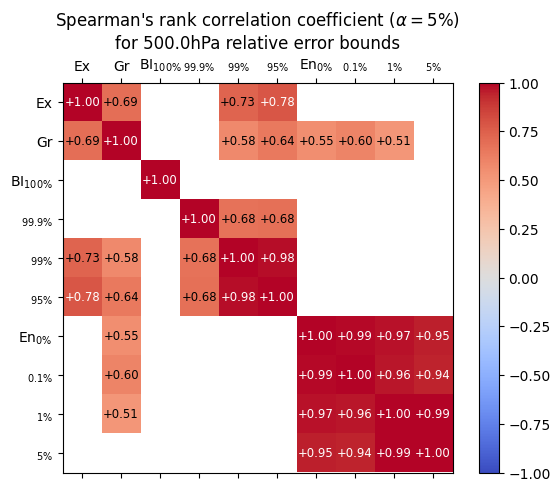

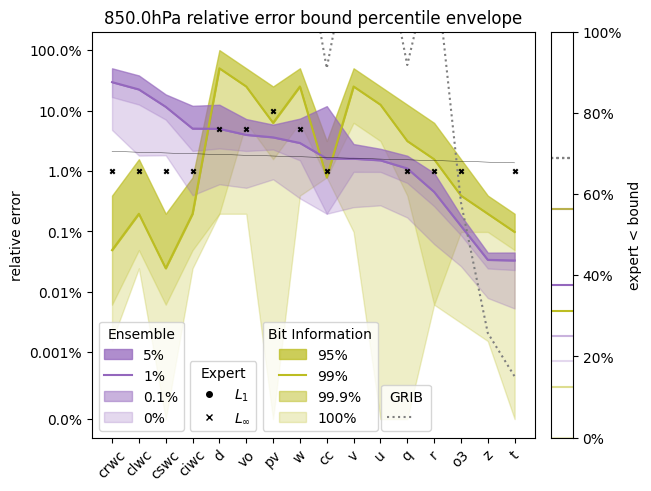

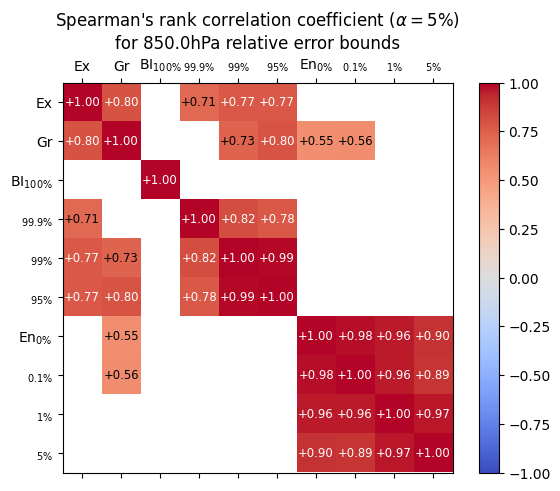

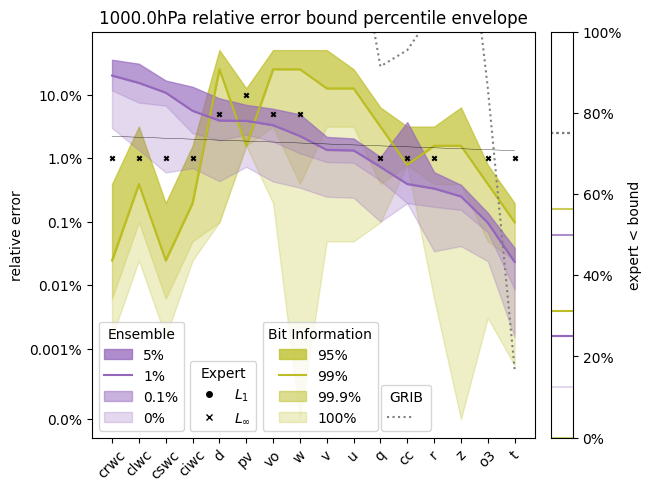

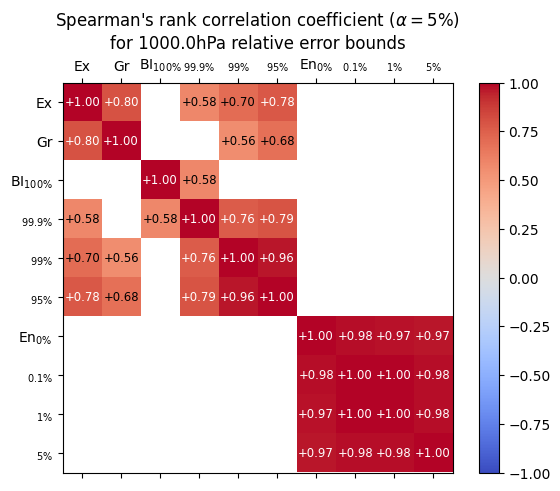

In [24]:
for p, pressure_ensemble_p in pressure_ensemble.items():
    fig, (ax, axr) = plt.subplots(
        1, 2, width_ratios=[20, 1], gridspec_kw={"wspace": 0.05}, layout="constrained"
    )

    ax.set_title(f"{p} relative error bound percentile envelope")
    ax.set_ylabel("relative error")

    scores = {v: e.relative[2] for v, e in pressure_ensemble_p.items()}
    v_sorted = sorted(scores.keys(), key=lambda k: scores[k], reverse=True)

    expert_xs = []
    expert_ys = []
    expert_pointwise = []
    for i, v in enumerate(v_sorted):
        expert_xs.append(i)
        expert_ys.append(pressure_expert[p][v].relative_value)
        expert_pointwise.append(pressure_expert[p][v].absolute_kind == "max")
    expert_pointwise = np.array(expert_pointwise)
    ax.scatter(
        np.array(expert_xs)[expert_pointwise],
        np.array(expert_ys)[expert_pointwise],
        s=10,
        marker="x",
        c="black",
        label="expert",
        zorder=9,
    )
    ax.scatter(
        np.array(expert_xs)[~expert_pointwise],
        np.array(expert_ys)[~expert_pointwise],
        s=4,
        marker="o",
        c="black",
        label="expert",
        zorder=9,
    )

    expert_fit = Polynomial.fit(
        np.array(expert_xs)[np.array(expert_ys) > 0],
        np.log(np.array(expert_ys)[np.array(expert_ys) > 0]),
        deg=1,
    )
    ax.plot(expert_xs, np.exp(expert_fit(expert_xs)), zorder=11, lw=0.25, c="black")

    ax.fill_between(
        range(len(v_sorted)),
        [pressure_bit_information[p][v].relative[0] for v in v_sorted],
        [pressure_bit_information[p][v].relative[2] for v in v_sorted],
        alpha=0.25,
        color="tab:olive",
        label="100%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [pressure_bit_information[p][v].relative[1] for v in v_sorted],
        [pressure_bit_information[p][v].relative[2] for v in v_sorted],
        alpha=0.25,
        color="tab:olive",
        label="99.9%",
    )
    ax.plot(
        [pressure_bit_information[p][v].relative[2] for v in v_sorted],
        color="tab:olive",
        label="99%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [pressure_bit_information[p][v].relative[3] for v in v_sorted],
        [pressure_bit_information[p][v].relative[2] for v in v_sorted],
        alpha=0.66,
        color="tab:olive",
        label="95%",
    )

    ax.fill_between(
        range(len(v_sorted)),
        [pressure_ensemble_p[v].relative[0] for v in v_sorted],
        [pressure_ensemble_p[v].relative[2] for v in v_sorted],
        alpha=0.25,
        color="tab:purple",
        label="0%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [pressure_ensemble_p[v].relative[1] for v in v_sorted],
        [pressure_ensemble_p[v].relative[2] for v in v_sorted],
        alpha=0.25,
        color="tab:purple",
        label="0.1%",
    )
    ax.plot(
        [pressure_ensemble_p[v].relative[2] for v in v_sorted],
        color="tab:purple",
        label="1%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [pressure_ensemble_p[v].relative[3] for v in v_sorted],
        [pressure_ensemble_p[v].relative[2] for v in v_sorted],
        alpha=0.66,
        color="tab:purple",
        label="5%",
    )

    ax.set_yscale("symlog", linthresh=1e-5)

    ylim = ax.get_ylim()

    ax.plot(
        [
            (
                pressure_grib[p][v]
                * (pressure_range[p][v].max - pressure_range[p][v].min)
                / pressure_range[p][v].min_abs
            )
            if pressure_range[p][v].min_abs > 0
            else np.nan
            for v in v_sorted
        ],
        color="tab:gray",
        ls=":",
    )

    ax.set_ylim(*ylim)

    l1 = ax.legend(
        handles=[
            mpl.patches.Patch(color="tab:purple", alpha=0.75, label="5%"),
            mpl.lines.Line2D([0], [0], color="tab:purple", label="1%"),
            mpl.patches.Patch(color="tab:purple", alpha=0.5, label="0.1%"),
            mpl.patches.Patch(color="tab:purple", alpha=0.25, label="0%"),
        ],
        ncol=1,
        loc="lower left",
        title="Ensemble",
    )
    l2 = ax.legend(
        handles=[
            mpl.lines.Line2D(
                [0],
                [0],
                markersize=4,
                marker="o",
                color="none",
                markerfacecolor="black",
                markeredgecolor="black",
                label="$L_1$",
            ),
            mpl.lines.Line2D(
                [0],
                [0],
                markersize=4,
                marker="x",
                color="none",
                markerfacecolor="black",
                markeredgecolor="black",
                label=r"$L_{\infty}$",
            ),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.205, 0, 1, 1),
        title="Expert",
    )
    l3 = ax.legend(
        handles=[
            mpl.patches.Patch(color="tab:olive", alpha=0.75, label="95%"),
            mpl.lines.Line2D([0], [0], color="tab:olive", label="99%"),
            mpl.patches.Patch(color="tab:olive", alpha=0.5, label="99.9%"),
            mpl.patches.Patch(color="tab:olive", alpha=0.25, label="100%"),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.37, 0, 1, 1),
        title="Bit Information",
    )
    ax.legend(
        handles=[
            mpl.lines.Line2D([0], [0], color="tab:gray", ls=":"),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.6375, 0, 1, 1),
        title="GRIB",
    )
    ax.add_artist(l1)
    ax.add_artist(l2)
    ax.add_artist(l3)

    ax.set_xticks(range(len(v_sorted)))
    ax.set_xticklabels(v_sorted, rotation=45)
    # ax.set_xlabel("sorted by ensemble 1% bound")
    ax.yaxis.set_major_formatter(
        mtick.FuncFormatter(
            lambda x, pos=None: (
                f"{np.round(x * 100, 6)}%"
                if x == 0 or x >= 1e-5
                else f"{np.round(x * 100, 6):.0e}%"
            )
        )
    )

    axr.set_xticks([])
    axr.yaxis.tick_right()
    axr.yaxis.set_label_position("right")
    axr.set_ylabel("expert < bound")
    axr.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    axr.set_ylim(0, 1)

    for i, pt in enumerate(pressure_ensemble_p["u"].percentile):
        count = 0
        for v in pressure_expert[p]:
            count += (
                pressure_expert[p][v].relative_value
                < pressure_ensemble_p[v].relative[i]
            )
        axr.axhline(
            count / len(pressure_expert[p]),
            c="tab:purple",
            alpha=[0.25, 0.5, 1.0, 0.75][i],
        )

    for i, pt in enumerate(pressure_ensemble_p["u"].percentile):
        count = 0
        for v in pressure_expert[p]:
            count += (
                pressure_expert[p][v].relative_value
                < pressure_bit_information[p][v].relative[i]
            )
        axr.axhline(
            count / len(pressure_expert[p]),
            c="tab:olive",
            alpha=[0.25, 0.5, 1.0, 0.75][i],
        )

    for i, pt in enumerate(pressure_ensemble_p["u"].percentile):
        count = 0
        for v in pressure_expert[p]:
            if pressure_range[p][v].min_abs > 0:
                count += pressure_expert[p][v].relative_value < (
                    pressure_grib[p][v]
                    * (pressure_range[p][v].max - pressure_range[p][v].min)
                    / pressure_range[p][v].min_abs
                )
            else:
                count += 1
        axr.axhline(count / len(pressure_expert[p]), c="tab:gray", ls=":")

    plt.show()
    fig.savefig(plots / f"pressure-{p.replace(' ', '')}-relative.pdf")

    observations = (
        [expert_ys]
        + [
            [
                (
                    pressure_grib[p][v]
                    * (pressure_range[p][v].max - pressure_range[p][v].min)
                    / pressure_range[p][v].min_abs
                )
                if pressure_range[p][v].min_abs > 0
                else np.nan
                for v in v_sorted
            ]
        ]
        + [
            [pressure_bit_information[p][v].relative[i] for v in v_sorted]
            for i in range(4)
        ]
        + [[pressure_ensemble_p[v].relative[i] for v in v_sorted] for i in range(4)]
    )

    spearmanr = stats.spearmanr(observations, axis=1, nan_policy="omit")

    fig, ax = plt.subplots(layout="constrained")

    alpha = 0.05

    m = ax.matshow(
        np.where(spearmanr.pvalue < alpha, spearmanr.statistic, np.nan),
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
    )

    X, Y = np.meshgrid(np.arange(len(observations)), np.arange(len(observations)))
    for x, y in zip(X.flatten(), Y.flatten()):
        if spearmanr.pvalue[x, y] < alpha:
            ax.text(
                x,
                y,
                f"{np.format_float_positional(spearmanr.statistic[x, y], precision=2, min_digits=2, sign=True)}",
                va="center",
                ha="center",
                fontsize="small",
                color="white" if np.abs(spearmanr.statistic[x, y]) > 0.75 else "black",
            )

    ax.set_title(
        r"Spearman's rank correlation coefficient ($\alpha = 5\%$)"
        + f"\nfor {p} relative error bounds"
    )

    ax.set_xticks(range(len(observations)))
    ax.set_xticklabels(
        [
            "Ex",
            "Gr",
            r"BI$_{100\%}$",
            r"$_{99.9\%}$",
            r"$_{99\%}$",
            r"$_{95\%}$",
            r"En$_{0\%}$",
            r"$_{0.1\%}$",
            r"$_{1\%}$",
            r"$_{5\%}$",
        ]
    )

    ax.set_yticks(range(len(observations)))
    ax.set_yticklabels(
        [
            "Ex",
            "Gr",
            r"BI$_{100\%}$",
            r"$_{99.9\%}$",
            r"$_{99\%}$",
            r"$_{95\%}$",
            r"En$_{0\%}$",
            r"$_{0.1\%}$",
            r"$_{1\%}$",
            r"$_{5\%}$",
        ]
    )

    fig.colorbar(m)

    plt.show()
    fig.savefig(plots / f"pressure-{p.replace(' ', '')}-relative-rank.pdf")